# Attack Timeline — Engelen-cleaned CIC-IDS2017

**Notebook 03 of EDA series**
**Author:** Bradly Morein (UP2088701)
**Date:** 27 April 2026

## Purpose

Characterise the temporal structure of attacks across the five-day capture 
week. Three questions:

1. **When during the day do attacks happen?** CIC scheduled attacks at 
   specific windows; we want to see them clearly.
2. **What is the temporal density of each attack type?** DoS floods generate 
   massive flow counts in narrow windows; Heartbleed and Infiltration 
   trickle. Shape matters for the Discussion chapter.
3. **What does benign baseline traffic look like?** Office-hours patterns, 
   lunch-break dips, infrastructure noise.

Outputs:

- **Plot A** — flows per minute, benign vs attack, all five days.
- **Plot B** — attack flows per minute by attack type, focused on Wednesday.
- **Plot C** — heatmap of attack labels × hour-of-day.

Plots will be saved to `reports/figures/` for inclusion in Methodology 
chapter §4.2.

In [1]:
"""Imports and notebook-wide settings."""
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Repository root resolution
REPO_ROOT = Path.cwd()
while not (REPO_ROOT / ".git").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
PARQUET_DIR = REPO_ROOT / "data" / "interim" / "cicids2017-engelen"
FIGURES_DIR = REPO_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# Matplotlib defaults — clean, publication-style
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,         # high-res when saving for the dissertation
    "figure.figsize": (12, 4),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

day_files = sorted(PARQUET_DIR.glob("*.parquet"))
print(f"Repo root:   {REPO_ROOT}")
print(f"Figures dir: {FIGURES_DIR}")
print(f"Files: {len(day_files)} Parquet files")

Repo root:   /home/brad/projects/dissertation
Figures dir: /home/brad/projects/dissertation/reports/figures
Files: 5 Parquet files


## Step 1 — Parse timestamps

The Timestamp column is in the format `DD/MM/YYYY HH:MM:SS AM/PM`, e.g. 
`03/07/2017 01:56:34 PM`. This is European date order with US 12-hour time 
— a hybrid format that pandas won't guess correctly without explicit help.

We'll parse with the explicit format string `%d/%m/%Y %I:%M:%S %p`:
- `%d` — day (01–31)
- `%m` — month (01–12)
- `%Y` — four-digit year
- `%I` — 12-hour clock (01–12) — note uppercase I, not lowercase L
- `%M` — minute
- `%S` — second
- `%p` — AM/PM marker

In [2]:
"""Load each day, parse Timestamp, attach a parsed datetime column."""

# We only need Timestamp + Label for timeline analysis — much faster than loading everything
USECOLS = ["Timestamp", "Label"]

per_day = {}
for path in day_files:
    day = path.stem.replace("-WorkingHours", "")
    df = pd.read_parquet(path, columns=USECOLS)
    
    # Parse with explicit format. errors='coerce' turns unparseable rows
    # into NaT so we can detect them, rather than crashing the whole load.
    df["dt"] = pd.to_datetime(
        df["Timestamp"],
        format="%d/%m/%Y %I:%M:%S %p",
        errors="coerce",
    )
    
    per_day[day] = df

# Sanity check: did anything fail to parse?
print(f"{'Day':<12} {'Total':>10} {'Parsed':>10} {'Failed':>10} {'Min datetime':>22} {'Max datetime':>22}")
print("-" * 90)
for day, df in per_day.items():
    n_total  = len(df)
    n_failed = df["dt"].isna().sum()
    n_parsed = n_total - n_failed
    dt_min = df["dt"].min()
    dt_max = df["dt"].max()
    print(f"{day:<12} {n_total:>10,} {n_parsed:>10,} {n_failed:>10,} {str(dt_min):>22} {str(dt_max):>22}")

Day               Total     Parsed     Failed           Min datetime           Max datetime
------------------------------------------------------------------------------------------
Friday          547,915    547,915          0    2017-07-07 13:59:50    2017-07-07 22:02:40
Monday          371,749    371,749          0    2017-07-03 13:55:58    2017-07-03 22:01:34
Thursday        362,368    362,368          0    2017-07-06 13:59:00    2017-07-06 22:04:36
Tuesday         322,003    322,003          0    2017-07-04 13:53:44    2017-07-04 22:00:30
Wednesday       496,779    496,779          0    2017-07-05 13:42:42    2017-07-05 22:10:14


## Observations from timestamp parsing

- **All 2,100,814 timestamps parsed successfully** with the explicit format 
  `%d/%m/%Y %I:%M:%S %p`. No failures — confirms the dataset uses a 
  consistent DD/MM/YYYY 12-hour format throughout.

- **Capture period: 3–7 July 2017 (Monday to Friday).** Confirmed via the 
  per-day min/max datetimes.

- **Capture window per day: approximately 14:00 to 22:00 local time** 
  (8 hours × 5 days ≈ 40 hours total). This is *not* the 9-to-5 "office 
  hours" assumed in some descriptions of the dataset; it is afternoon and 
  evening traffic. The implication is that the captured benign baseline 
  reflects typical end-of-day office activity (later afternoon work, 
  end-of-day backups, after-hours infrastructure noise) rather than morning 
  startup or full-day patterns. **Note for Methodology chapter §4.2.**

Saved: reports/figures/fig_attack_timeline_per_day.png


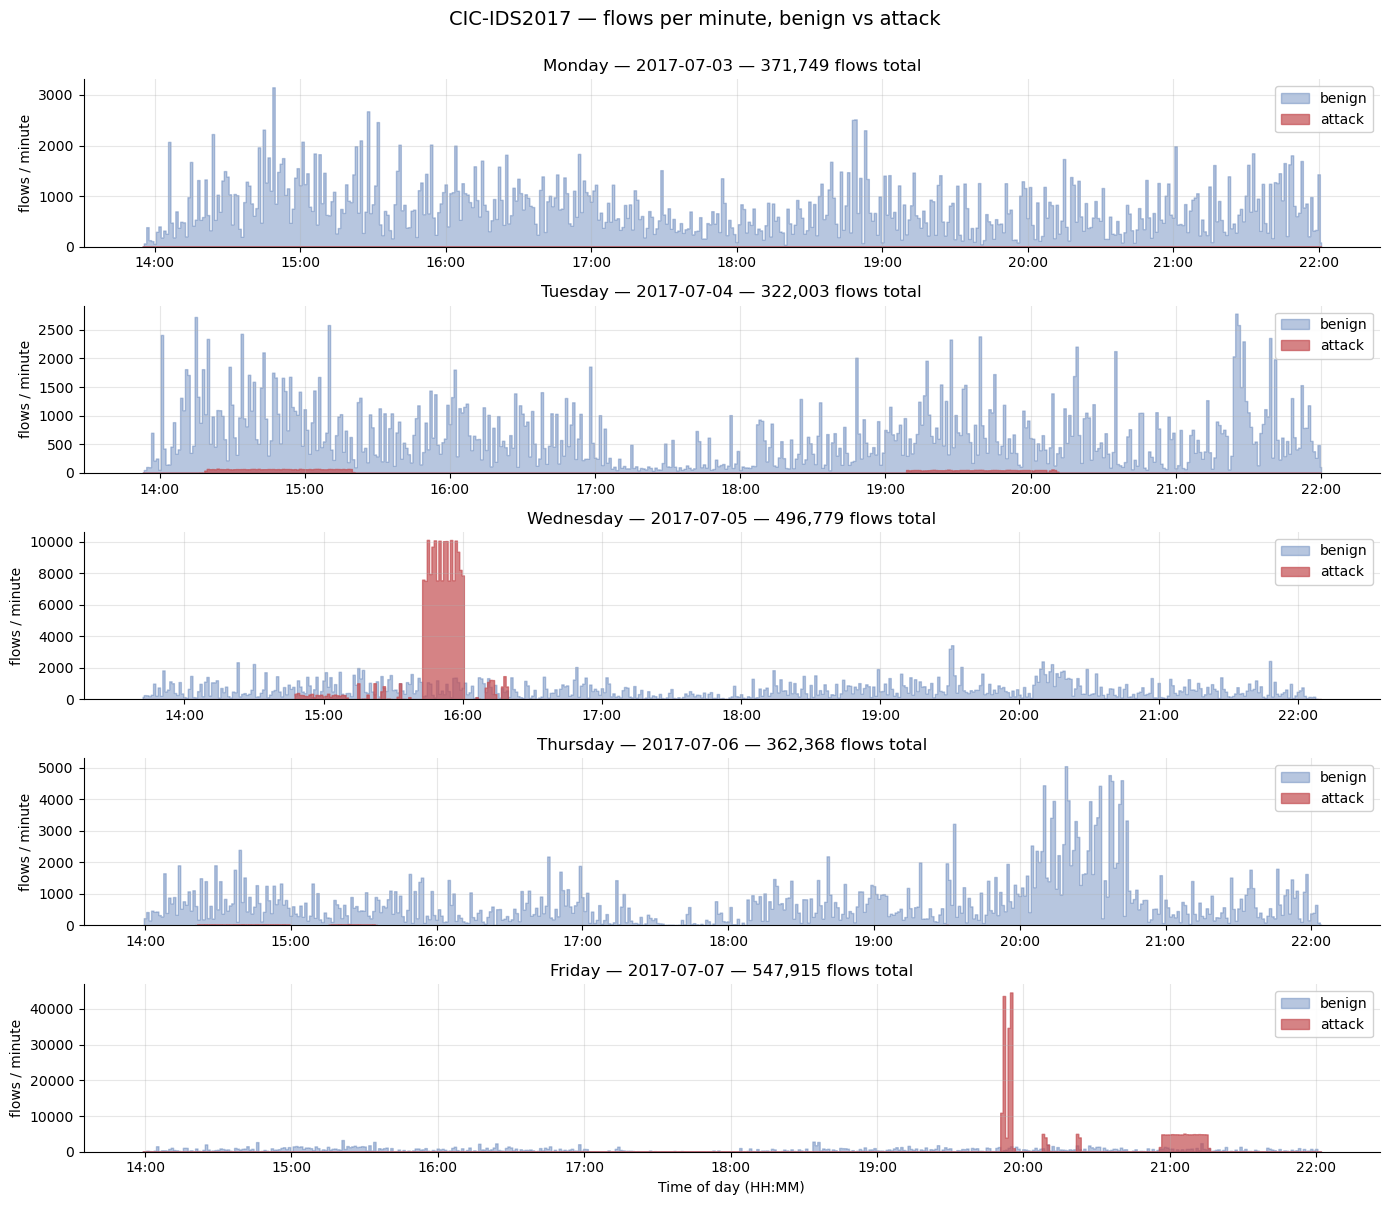

In [3]:
"""Plot A — flows per minute, benign vs attack, side-by-side per day."""

# Aggregate flows per minute per day, separated by class
def per_minute_counts(df):
    """Return DataFrame indexed by minute with columns benign/attack."""
    df = df.copy()
    df["minute"] = df["dt"].dt.floor("min")     # round each timestamp down to the minute
    df["is_attack"] = (df["Label"] != "BENIGN").astype(int)
    grouped = df.groupby("minute").agg(
        total=("Label", "size"),
        attack=("is_attack", "sum"),
    )
    grouped["benign"] = grouped["total"] - grouped["attack"]
    return grouped

# Order the days chronologically (Mon→Fri) for nice subplot order
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

fig, axes = plt.subplots(5, 1, figsize=(14, 12), sharex=False)

for ax, day in zip(axes, day_order):
    df = per_day[day]
    counts = per_minute_counts(df)
    
    ax.fill_between(counts.index, counts["benign"], step="mid", 
                    alpha=0.4, label="benign", color="#4C72B0")
    ax.fill_between(counts.index, counts["attack"], step="mid", 
                    alpha=0.7, label="attack", color="#C44E52")
    
    ax.set_title(f"{day} — {df['dt'].min().date()} — {len(df):,} flows total")
    ax.set_ylabel("flows / minute")
    ax.legend(loc="upper right", framealpha=0.9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    
    # Mild visual aid: the attack peak height should be visible
    ax.set_ylim(bottom=0)

axes[-1].set_xlabel("Time of day (HH:MM)")
fig.suptitle("CIC-IDS2017 — flows per minute, benign vs attack", fontsize=14, y=1.00)
fig.tight_layout()

# Save for use in Methodology chapter §4.2
out_path = FIGURES_DIR / "fig_attack_timeline_per_day.png"
fig.savefig(out_path, bbox_inches="tight")
print(f"Saved: {out_path.relative_to(REPO_ROOT)}")

plt.show()

## Observations from Plot A — flows per minute, benign vs attack

### Monday — visually confirms benign-only training set

All 371,749 flows are benign. No red regions anywhere. Monday's data is 
suitable as the training distribution for the unsupervised autoencoder.

### Tuesday — afternoon brute-force window only

Brute-force activity (likely SSH-Patator) is visible in a roughly one-hour 
window between approximately 14:30 and 15:30. CIC's documentation describes 
two attack windows on Tuesday (FTP-Patator from ~9:20–10:20, SSH-Patator 
from ~14:00–15:00 local time). **Only the afternoon window is captured**, 
because the dataset capture period itself starts around 14:00.

**Note on the dataset characterisation:** CIC-IDS2017 captures only 
afternoon-and-evening traffic (approximately 14:00–22:00 each weekday). 
This means *morning attack scenarios* documented in the CIC schedule 
do not appear in the dataset. Worth flagging in Methodology §4.2.

### Wednesday — DoS Hulk dominates

The DoS Hulk attack reaches sustained rates of approximately 10,000 flows 
per minute (≈167 flows/second), forming a wide red mountain that visually 
swamps the benign baseline. This high temporal density is consistent with 
DoS Hulk's 158,469-flow count in the label distribution and explains why 
this attack class will be trivially classifiable by any reasonable model.

### Thursday — visually almost identical to a benign day

Despite containing web attacks (Brute Force, XSS, SQL Injection) and 
Infiltration activity, Thursday's plot shows essentially no visible red. 
Total attacks: 2,104 of 362,368 flows (0.58%). **This is the central 
operational challenge:** dangerous attacks (Infiltration: 32 flows total) 
leave near-invisible temporal footprints. Detection cannot rely on 
timing-based heuristics for this class of attack.

### Friday — distinct attack bursts

Approximately 4 sharp red bursts are visible across the afternoon, 
corresponding to PortScan, DDoS, and Bot scheduled sessions. Unlike 
Wednesday's sustained mountain, Friday's attacks are episodic — distinct 
high-rate windows separated by benign intervals. This contrasts with the 
Wednesday DoS pattern and illustrates that "attack" in CIC-IDS2017 is not 
a single phenomenon but several with markedly different temporal signatures.

### Implications for modelling

1. **Model evaluation must address both flood-style attacks (sustained, 
   high-volume) and stealth attacks (sparse, low-volume).** A single 
   accuracy metric will not distinguish a model that catches DoS Hulk 
   and misses Infiltration from one that catches both.
2. **Temporal-feature-based models (LSTM with packet sequences) may 
   capture flood-style attacks effectively but will struggle on stealth 
   attacks where there is no temporal signature to learn from.**
3. **Per-class evaluation in Chapter 6 must report Infiltration, 
   Heartbleed, and Web Attack performance separately**, not just 
   macro-averaged. Macro-averaged metrics will be dominated by the 
   high-volume classes.

### Figure status

Saved to `reports/figures/fig_attack_timeline_per_day.png` (300dpi, 
publication quality). Candidate figure for **Methodology chapter §4.2** 
(dataset characterisation).